In [ ]:
# 1. Connect Colab to your Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Set the path directly to your train folder in Drive
train_dir = '/content/drive/MyDrive/BD3_original_dataset/train'

# 3. Import libraries and set up data generators
!pip install tensorflow
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Setup the generator with data augmentation and a 20% validation split
datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)

# Load Training Data
print("Loading Training Data:")
train_data = datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='training'
)

# Load Validation Data
print("\nLoading Validation Data:")
val_data = datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='validation'
)

# Print mapping to verify all 9 classes are found
print("\nClass Mapping:", train_data.class_indices)

Mounted at /content/drive
Loading Training Data:
Found 3677 images belonging to 9 classes.

Loading Validation Data:
Found 915 images belonging to 9 classes.

Class Mapping: {'algae': 0, 'major_crack': 1, 'minor_crack': 2, 'mold': 3, 'peeling': 4, 'plain': 5, 'spalling': 6, 'stain': 7, 'water_seepage': 8}


In [ ]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
import tensorflow as tf

print("Downloading VGG16 Base Model...")
# 1. Load the pre-trained VGG16 base
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# 2. Freeze the base model so we don't ruin its pre-trained weights
base_model.trainable = False

# 3. Build ConstructGuard Model
model = Sequential([
    base_model,
    Flatten(),
    Dense(512, activation='relu'),
    Dropout(0.5), # Helps prevent overfitting
    Dense(9, activation='softmax') # 9 outputs for your 9 specific classes
])

# 4. Compile the model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("\nModel built successfully! Starting training...")

# 5. Train the model
# We are using 10 epochs to start. This might take 10-20 minutes depending on the GPU.
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10
)

# 6. Save the finished model back to your Drive so you don't lose it!
model_save_path = '/content/drive/MyDrive/ConstructGuard_VGG16_Final.h5'
model.save(model_save_path)
print(f"\nTraining Complete! Model saved to: {model_save_path}")


Model built successfully! Starting training...
Epoch 1/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 1711s 15s/step - accuracy: 0.4384 - loss: 1.5674 - val_accuracy: 0.5716 - val_loss: 1.2063
Epoch 2/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 81s 702ms/step - accuracy: 0.5806 - loss: 1.1519 - val_accuracy: 0.6230 - val_loss: 1.1140
Epoch 3/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 82s 711ms/step - accuracy: 0.6269 - loss: 1.0531 - val_accuracy: 0.6426 - val_loss: 1.0104
Epoch 4/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 81s 709ms/step - accuracy: 0.6614 - loss: 0.9652 - val_accuracy: 0.6656 - val_loss: 0.9541
Epoch 5/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 81s 707ms/step - accuracy: 0.6775 - loss: 0.9026 - val_accuracy: 0.6634 - val_loss: 0.9501
Epoch 6/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 82s 709ms/step - accuracy: 0.6919 - loss: 0.8636 - val_accuracy: 0.6984 - val_loss: 0.8860
Epoch 7/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 83s 726ms/step - accuracy: 0.6951 - loss: 0.8431 - val_accuracy: 0.6765 - val_loss: 0.8826
Epoch 8/10
115/115 ━━━━━━━━━━━━━━━━


Training Complete! Model saved to: /content/drive/MyDrive/ConstructGuard_VGG16_Final.h5


In [ ]:
import numpy as np
from sklearn.utils import class_weight

# 1. Get the actual labels from your training data
train_classes = train_data.classes

# 2. Calculate the weights automatically
# 'balanced' tells it to heavily weight the rare classes and lightly weight the common ones
class_weights_array = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_classes),
    y=train_classes
)

# 3. Keras requires these weights in a dictionary format
class_weights_dict = dict(enumerate(class_weights_array))

# 4. Print them out to see the difference
print("Class Weights Calculated:")
for class_index, weight in class_weights_dict.items():
    class_name = list(train_data.class_indices.keys())[class_index]
    print(f"{class_name} (Class {class_index}): Weight = {weight:.2f}")

Class Weights Calculated:
algae (Class 0): Weight = 0.84
major_crack (Class 1): Weight = 0.86
minor_crack (Class 2): Weight = 0.82
mold (Class 3): Weight = 2.65
peeling (Class 4): Weight = 0.66
plain (Class 5): Weight = 0.85
spalling (Class 6): Weight = 1.02
stain (Class 7): Weight = 0.98
water_seepage (Class 8): Weight = 2.88


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# ==========================================
# STEP 2: FINE-TUNING VGG16
# ==========================================
print("Unfreezing the top layers of VGG16...")

# Unfreeze the base model
base_model.trainable = True

# VGG16 has many layers. We only want to unfreeze the last block (block5).
# If we unfreeze the early layers, the model will forget basic shapes!
for layer in base_model.layers:
    if layer.name.startswith('block5'):
        layer.trainable = True
    else:
        layer.trainable = False

# We MUST recompile the model after changing trainable layers.
# CRITICAL: We use a VERY SMALL learning rate (0.00001) so we don't
# destroy the pre-trained weights, we just gently nudge them.
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# ==========================================
# STEP 3: THE "BABYSITTER" CALLBACKS
# ==========================================

# 1. Reduce Learning Rate on Plateau:
# If validation loss stops improving for 3 epochs, drop the learning rate to take smaller steps
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-7,
    verbose=1
)

# 2. Early Stopping:
# If validation loss stops improving for 6 epochs, STOP training.
# restore_best_weights=True ensures you keep the best version, not the overfitted version.
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=6,
    restore_best_weights=True,
    verbose=1
)

# ==========================================
# THE FINAL TRAINING RUN
# ==========================================
print("\nStarting Fine-Tuning with Class Weights and Callbacks...")

# We can set epochs high (like 30) because EarlyStopping will catch it if it finishes early.
history_finetune = model.fit(
    train_data,
    validation_data=val_data,
    epochs=30,
    class_weight=class_weights_dict, # Applying your Step 1 Band-Aid
    callbacks=[reduce_lr, early_stop] # Applying your Step 3 Babysitters
)

# Save the ultimate version!
final_model_path = '/content/drive/MyDrive/ConstructGuard_VGG16_Ultimate.h5'
model.save(final_model_path)
print(f"\nUltimate Model saved to: {final_model_path}")

Unfreezing the top layers of VGG16...

Starting Fine-Tuning with Class Weights and Callbacks...
Epoch 1/30
115/115 ━━━━━━━━━━━━━━━━━━━━ 93s 754ms/step - accuracy: 0.7653 - loss: 0.6665 - val_accuracy: 0.7399 - val_loss: 0.7573 - learning_rate: 1.0000e-05
Epoch 2/30
115/115 ━━━━━━━━━━━━━━━━━━━━ 82s 711ms/step - accuracy: 0.7906 - loss: 0.5907 - val_accuracy: 0.7563 - val_loss: 0.7084 - learning_rate: 1.0000e-05
Epoch 3/30
115/115 ━━━━━━━━━━━━━━━━━━━━ 81s 701ms/step - accuracy: 0.8036 - loss: 0.5469 - val_accuracy: 0.7519 - val_loss: 0.6704 - learning_rate: 1.0000e-05
Epoch 4/30
115/115 ━━━━━━━━━━━━━━━━━━━━ 80s 692ms/step - accuracy: 0.8221 - loss: 0.5194 - val_accuracy: 0.7650 - val_loss: 0.6852 - learning_rate: 1.0000e-05
Epoch 5/30
115/115 ━━━━━━━━━━━━━━━━━━━━ 81s 707ms/step - accuracy: 0.8352 - loss: 0.4665 - val_accuracy: 0.7694 - val_loss: 0.6629 - learning_rate: 1.0000e-05
Epoch 6/30
115/115 ━━━━━━━━━━━━━━━━━━━━ 82s 714ms/step - accuracy: 0.8385 - loss: 0.4408 - val_accuracy: 0.78


Ultimate Model saved to: /content/drive/MyDrive/ConstructGuard_VGG16_Ultimate.h5


In [ ]:
import os
import shutil

# 1. Define paths
original_data_path = '/content/drive/MyDrive/BD3_original_dataset/train'
base_target_path = '/content/drive/MyDrive/ConstructGuard_Cascaded'

# 2. Define our Two-Step Architecture mapping
architecture = {
    # Dataset 1: The High-Level Router
    'Router_Data': {
        'Healthy': ['plain'],
        'Structural': ['major_crack', 'minor_crack', 'spalling'],
        'Moisture': ['algae', 'mold', 'stain', 'water_seepage'],
        'Surface': ['peeling']
    },
    # Dataset 2: The Moisture Specialist
    'Moisture_Specialist_Data': {
        'algae': ['algae'],
        'mold': ['mold'],
        'stain': ['stain'],
        'water_seepage': ['water_seepage']
    },
    # Dataset 3: The Structural Specialist
    'Structural_Specialist_Data': {
        'major_crack': ['major_crack'],
        'minor_crack': ['minor_crack'],
        'spalling': ['spalling']
    }
}

print("Initializing ConstructGuard Cascaded Architecture...\n")

# 3. Build the directories and copy the files
for dataset_name, categories in architecture.items():
    dataset_dir = os.path.join(base_target_path, dataset_name)
    print(f"--- Building {dataset_name} ---")

    for target_class, original_folders in categories.items():
        # Create the target class folder (e.g., .../Router_Data/Moisture)
        target_class_dir = os.path.join(dataset_dir, target_class)
        os.makedirs(target_class_dir, exist_ok=True)

        for folder in original_folders:
            source_folder = os.path.join(original_data_path, folder)

            if os.path.exists(source_folder):
                # Count files to show progress
                files = [f for f in os.listdir(source_folder) if os.path.isfile(os.path.join(source_folder, f))]
                print(f"  Copying {len(files)} images from '{folder}' into '{target_class}'...")

                for filename in files:
                    src_file = os.path.join(source_folder, filename)
                    # Prefix filename to avoid naming collisions when combining folders
                    dst_file = os.path.join(target_class_dir, f"{folder}_{filename}")
                    shutil.copy2(src_file, dst_file)
            else:
                print(f"  WARNING: Could not find {source_folder}")

print("\n✅ Data Reorganization Complete!")
print(f"Your new architecture datasets are ready at: {base_target_path}")

Initializing ConstructGuard Cascaded Architecture...

--- Building Router_Data ---
  Copying 600 images from 'plain' into 'Healthy'...
  Copying 593 images from 'major_crack' into 'Structural'...
  Copying 624 images from 'minor_crack' into 'Structural'...
  Copying 500 images from 'spalling' into 'Structural'...
  Copying 609 images from 'algae' into 'Moisture'...
  Copying 192 images from 'mold' into 'Moisture'...
  Copying 521 images from 'stain' into 'Moisture'...
  Copying 177 images from 'water_seepage' into 'Moisture'...
  Copying 776 images from 'peeling' into 'Surface'...
--- Building Moisture_Specialist_Data ---
  Copying 609 images from 'algae' into 'algae'...
  Copying 192 images from 'mold' into 'mold'...
  Copying 521 images from 'stain' into 'stain'...
  Copying 177 images from 'water_seepage' into 'water_seepage'...
--- Building Structural_Specialist_Data ---
  Copying 593 images from 'major_crack' into 'major_crack'...
  Copying 624 images from 'minor_crack' into 'mino

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# 1. Point to the new Router Dataset
router_dir = '/content/drive/MyDrive/ConstructGuard_Cascaded/Router_Data'

# 2. Setup Data Generators
datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    horizontal_flip=True,
    validation_split=0.2
)

print("Loading Router Training Data:")
train_router = datagen.flow_from_directory(
    router_dir, target_size=(224, 224), batch_size=32,
    class_mode='categorical', subset='training'
)

print("\nLoading Router Validation Data:")
val_router = datagen.flow_from_directory(
    router_dir, target_size=(224, 224), batch_size=32,
    class_mode='categorical', subset='validation', shuffle=False
)

# 3. Build the Router Model (4 Classes)
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False # Freeze base for the router, it doesn't need fine-tuning for broad categories

router_model = Sequential([
    base_model,
    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(4, activation='softmax') # 4 outputs for Healthy, Moisture, Structural, Surface
])

router_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 4. Train the Router
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

print("\nTraining Router Model...")
history_router = router_model.fit(
    train_router,
    validation_data=val_router,
    epochs=15,
    callbacks=[early_stop]
)

# 5. Save it
router_model.save('/content/drive/MyDrive/ConstructGuard_Router.h5')
print("\nRouter Model Saved!")

Loading Router Training Data:
Found 3675 images belonging to 4 classes.

Loading Router Validation Data:
Found 917 images belonging to 4 classes.

Training Router Model...
Epoch 1/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 109s 926ms/step - accuracy: 0.5785 - loss: 0.9853 - val_accuracy: 0.8201 - val_loss: 0.5873
Epoch 2/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 125s 792ms/step - accuracy: 0.7067 - loss: 0.7445 - val_accuracy: 0.8364 - val_loss: 0.4886
Epoch 3/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 79s 686ms/step - accuracy: 0.7344 - loss: 0.6752 - val_accuracy: 0.8397 - val_loss: 0.4556
Epoch 4/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 80s 692ms/step - accuracy: 0.7652 - loss: 0.6098 - val_accuracy: 0.8615 - val_loss: 0.4225
Epoch 5/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 79s 688ms/step - accuracy: 0.7872 - loss: 0.5507 - val_accuracy: 0.8866 - val_loss: 0.3816
Epoch 6/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 81s 703ms/step - accuracy: 0.7796 - loss: 0.5505 - val_accuracy: 0.8735 - val_loss: 0.3776
Epoch 7/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 


Router Model Saved!


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.utils import class_weight
import numpy as np

# 1. Point to the Moisture Specialist Dataset
moisture_dir = '/content/drive/MyDrive/ConstructGuard_Cascaded/Moisture_Specialist_Data'

# 2. Setup Data Generators
datagen = ImageDataGenerator(
    rescale=1./255, rotation_range=20, width_shift_range=0.2,
    height_shift_range=0.2, horizontal_flip=True, validation_split=0.2
)

print("Loading Moisture Training Data...")
train_moisture = datagen.flow_from_directory(
    moisture_dir, target_size=(224, 224), batch_size=32,
    class_mode='categorical', subset='training'
)

print("\nLoading Moisture Validation Data...")
val_moisture = datagen.flow_from_directory(
    moisture_dir, target_size=(224, 224), batch_size=32,
    class_mode='categorical', subset='validation', shuffle=False
)

# 3. Calculate Class Weights (Crucial for Water Seepage)
train_classes = train_moisture.classes
class_weights_array = class_weight.compute_class_weight(
    class_weight='balanced', classes=np.unique(train_classes), y=train_classes
)
moisture_weights = dict(enumerate(class_weights_array))
print("\nMoisture Class Weights:", moisture_weights)

# 4. Build and Fine-Tune the Model
print("\nBuilding Moisture Specialist...")
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = True

# Only unfreeze the final block for fine-tuning
for layer in base_model.layers:
    if layer.name.startswith('block5'):
        layer.trainable = True
    else:
        layer.trainable = False

moisture_model = Sequential([
    base_model,
    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(4, activation='softmax') # 4 outputs: algae, mold, stain, water_seepage
])

# Use a very low learning rate for fine-tuning
moisture_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy', metrics=['accuracy']
)

# 5. Callbacks & Training
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-7, verbose=1)
early_stop = EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True, verbose=1)

print("\nTraining Moisture Specialist...")
history_moisture = moisture_model.fit(
    train_moisture, validation_data=val_moisture, epochs=25,
    class_weight=moisture_weights, callbacks=[reduce_lr, early_stop]
)

# 6. Save the Specialist
moisture_model.save('/content/drive/MyDrive/ConstructGuard_Moisture_Specialist.h5')
print("\nMoisture Specialist Saved!")

Loading Moisture Training Data...
Found 1201 images belonging to 4 classes.

Loading Moisture Validation Data...
Found 298 images belonging to 4 classes.

Moisture Class Weights: {0: np.float64(0.6152663934426229), 1: np.float64(1.9496753246753247), 2: np.float64(0.7200239808153477), 3: np.float64(2.11443661971831)}

Building Moisture Specialist...

Training Moisture Specialist...
Epoch 1/25
38/38 ━━━━━━━━━━━━━━━━━━━━ 49s 1s/step - accuracy: 0.4713 - loss: 1.2807 - val_accuracy: 0.6946 - val_loss: 0.8511 - learning_rate: 1.0000e-05
Epoch 2/25
38/38 ━━━━━━━━━━━━━━━━━━━━ 28s 728ms/step - accuracy: 0.7427 - loss: 0.7849 - val_accuracy: 0.7450 - val_loss: 0.6460 - learning_rate: 1.0000e-05
Epoch 3/25
38/38 ━━━━━━━━━━━━━━━━━━━━ 28s 731ms/step - accuracy: 0.8002 - loss: 0.6296 - val_accuracy: 0.7483 - val_loss: 0.6936 - learning_rate: 1.0000e-05
Epoch 4/25
38/38 ━━━━━━━━━━━━━━━━━━━━ 28s 738ms/step - accuracy: 0.8226 - loss: 0.5399 - val_accuracy: 0.7785 - val_loss: 0.6541 - learning_rate: 1.


Moisture Specialist Saved!


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.utils import class_weight
import numpy as np

# 1. Point to the Structural Specialist Dataset
structural_dir = '/content/drive/MyDrive/ConstructGuard_Cascaded/Structural_Specialist_Data'

# 2. Setup Data Generators
datagen = ImageDataGenerator(
    rescale=1./255, rotation_range=20, width_shift_range=0.2,
    height_shift_range=0.2, horizontal_flip=True, validation_split=0.2
)

print("Loading Structural Training Data...")
train_structural = datagen.flow_from_directory(
    structural_dir, target_size=(224, 224), batch_size=32,
    class_mode='categorical', subset='training'
)

print("\nLoading Structural Validation Data...")
val_structural = datagen.flow_from_directory(
    structural_dir, target_size=(224, 224), batch_size=32,
    class_mode='categorical', subset='validation', shuffle=False
)

# 3. Calculate Class Weights
train_classes = train_structural.classes
class_weights_array = class_weight.compute_class_weight(
    class_weight='balanced', classes=np.unique(train_classes), y=train_classes
)
structural_weights = dict(enumerate(class_weights_array))
print("\nStructural Class Weights:", structural_weights)

# 4. Build and Fine-Tune the Model
print("\nBuilding Structural Specialist...")
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = True

# Unfreeze final block
for layer in base_model.layers:
    if layer.name.startswith('block5'):
        layer.trainable = True
    else:
        layer.trainable = False

structural_model = Sequential([
    base_model,
    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(3, activation='softmax') # ONLY 3 outputs: major_crack, minor_crack, spalling
])

structural_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy', metrics=['accuracy']
)

# 5. Callbacks & Training
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-7, verbose=1)
early_stop = EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True, verbose=1)

print("\nTraining Structural Specialist...")
history_structural = structural_model.fit(
    train_structural, validation_data=val_structural, epochs=25,
    class_weight=structural_weights, callbacks=[reduce_lr, early_stop]
)

# 6. Save the Specialist
structural_model.save('/content/drive/MyDrive/ConstructGuard_Structural_Specialist.h5')
print("\nStructural Specialist Saved!")

Loading Structural Training Data...
Found 1375 images belonging to 3 classes.

Loading Structural Validation Data...
Found 342 images belonging to 3 classes.

Structural Class Weights: {0: np.float64(0.9649122807017544), 1: np.float64(0.9166666666666666), 2: np.float64(1.1458333333333333)}

Building Structural Specialist...

Training Structural Specialist...
Epoch 1/25
43/43 ━━━━━━━━━━━━━━━━━━━━ 63s 1s/step - accuracy: 0.4698 - loss: 1.0406 - val_accuracy: 0.7047 - val_loss: 0.6883 - learning_rate: 1.0000e-05
Epoch 2/25
43/43 ━━━━━━━━━━━━━━━━━━━━ 32s 737ms/step - accuracy: 0.7084 - loss: 0.6541 - val_accuracy: 0.8070 - val_loss: 0.5060 - learning_rate: 1.0000e-05
Epoch 3/25
43/43 ━━━━━━━━━━━━━━━━━━━━ 33s 765ms/step - accuracy: 0.8102 - loss: 0.4751 - val_accuracy: 0.8304 - val_loss: 0.4093 - learning_rate: 1.0000e-05
Epoch 4/25
43/43 ━━━━━━━━━━━━━━━━━━━━ 32s 740ms/step - accuracy: 0.8327 - loss: 0.4274 - val_accuracy: 0.8392 - val_loss: 0.3739 - learning_rate: 1.0000e-05
Epoch 5/25
43/


Structural Specialist Saved!


Loading ConstructGuard Master AI...
Model loaded successfully!

=== CONSTRUCTGUARD INSPECTION INTERFACE ===
Please upload an image to inspect:


Saving cls00_019.jpg to cls00_019.jpg

Analyzing Image: cls00_019.jpg...


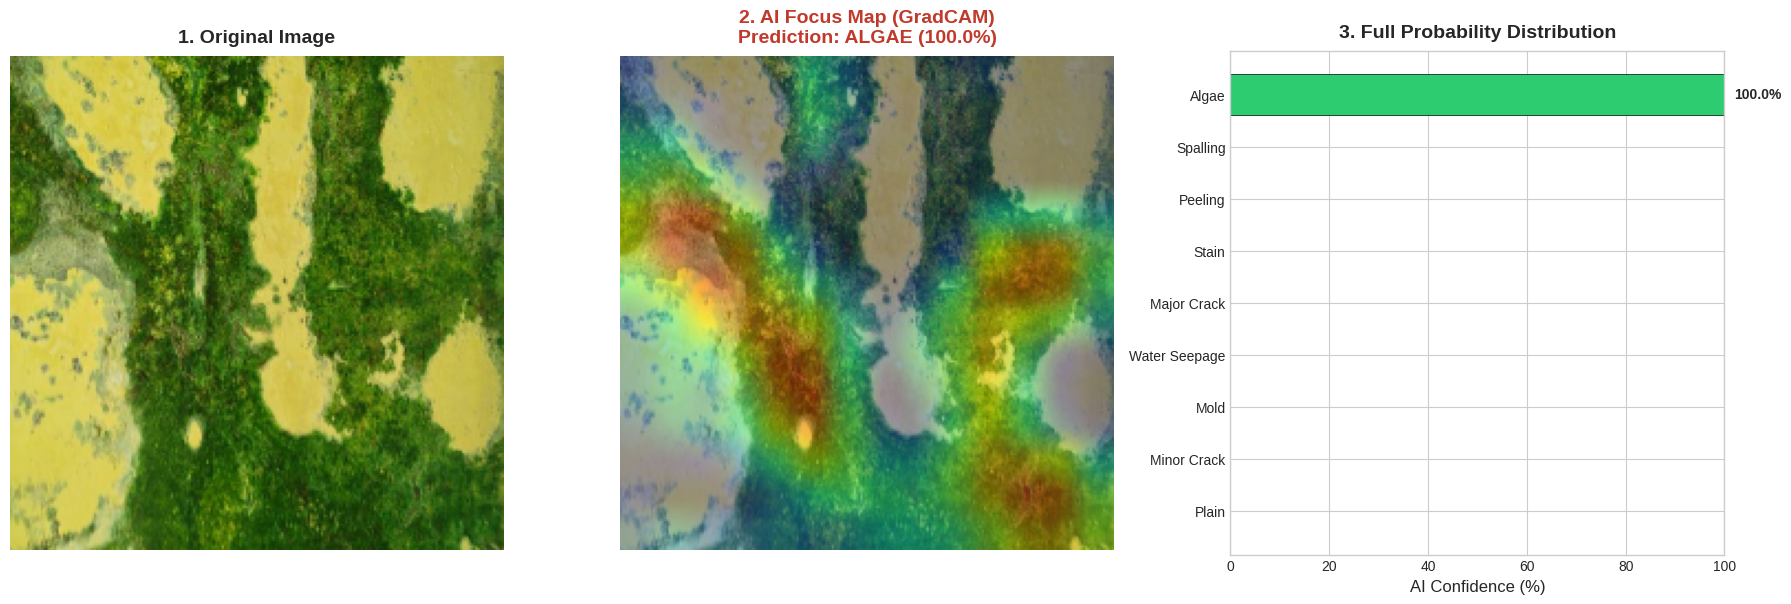

In [ ]:
import os
import numpy as np
import tensorflow as tf
import cv2
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from google.colab import files # Added for interactive upload

# ==========================================
# 1. LOAD MODEL & CONFIGURATION
# ==========================================
print("Loading ConstructGuard Master AI...")

MODEL_PATH = '/content/drive/MyDrive/ConstructGuard_VGG16_Ultimate.h5'
try:
    # Added compile=False to silence the compilation warning
    cg_model = tf.keras.models.load_model(MODEL_PATH, compile=False)
    print("Model loaded successfully!\n")
except Exception as e:
    print(f"Error loading model. Please check the file path: {e}")

cg_classes = [
    'algae', 'major_crack', 'minor_crack', 'mold',
    'peeling', 'plain', 'spalling', 'stain', 'water_seepage'
]

LAST_CONV_LAYER = 'block5_conv3'

# ==========================================
# 2. GRADCAM ENGINE (Cleaned & Silenced)
# ==========================================
def make_gradcam_heatmap(img_array, model, last_conv_layer_name):
    # Convert numpy array to Tensor to silence the input structure warning
    img_tensor = tf.convert_to_tensor(img_array)

    vgg_base = model.layers[0]
    last_conv_layer = vgg_base.get_layer(last_conv_layer_name)

    grad_model = tf.keras.models.Model(
        vgg_base.inputs,
        [last_conv_layer.output, vgg_base.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, base_outputs = grad_model(img_tensor)
        tape.watch(conv_outputs)

        preds = base_outputs
        for layer in model.layers[1:]:
            preds = layer(preds)

        top_pred_index = tf.argmax(preds[0])
        top_class_channel = preds[:, top_pred_index]

    grads = tape.gradient(top_class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)

    return heatmap.numpy()

def apply_heatmap(img_path, heatmap, alpha=0.5):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (224, 224))

    heatmap = np.uint8(255 * heatmap)

    # Updated to the modern Matplotlib call to silence the deprecation warning
    jet = plt.get_cmap("jet")
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap]

    jet_heatmap = tf.keras.utils.array_to_img(jet_heatmap)
    jet_heatmap = jet_heatmap.resize((img.shape[1], img.shape[0]))
    jet_heatmap = tf.keras.utils.img_to_array(jet_heatmap)

    superimposed_img = jet_heatmap * alpha + img
    superimposed_img = tf.keras.utils.array_to_img(superimposed_img)

    return img, superimposed_img

# ==========================================
# 3. DASHBOARD VISUALIZATION
# ==========================================
def display_constructguard_dashboard(original_img, superimposed_img, top_prediction, top_confidence, all_predictions_dict):
    fig = plt.figure(figsize=(18, 6))
    plt.style.use('seaborn-v0_8-whitegrid')

    # Panel 1: Original Image
    ax1 = plt.subplot(1, 3, 1)
    ax1.imshow(original_img)
    ax1.set_title("1. Original Image", fontsize=14, fontweight='bold', pad=10)
    ax1.axis('off')

    # Panel 2: GradCAM
    ax2 = plt.subplot(1, 3, 2)
    ax2.imshow(superimposed_img)
    title_2 = f"2. AI Focus Map (GradCAM)\nPrediction: {top_prediction.upper()} ({(top_confidence*100):.1f}%)"
    ax2.set_title(title_2, fontsize=14, fontweight='bold', color='#c0392b', pad=10)
    ax2.axis('off')

    # Panel 3: Probability Bar Chart
    ax3 = plt.subplot(1, 3, 3)

    sorted_preds = sorted(all_predictions_dict.items(), key=lambda item: item[1])
    classes = [item[0].replace('_', ' ').title() for item in sorted_preds]
    probabilities = [item[1] * 100 for item in sorted_preds]

    top_pred_formatted = top_prediction.replace('_', ' ').title()
    colors = ['#2ecc71' if cls == top_pred_formatted else '#bdc3c7' for cls in classes]

    bars = ax3.barh(classes, probabilities, color=colors, edgecolor='black', linewidth=0.5)

    ax3.set_title("3. Full Probability Distribution", fontsize=14, fontweight='bold', pad=10)
    ax3.set_xlabel('AI Confidence (%)', fontsize=12)
    ax3.set_xlim(0, 100)

    for bar in bars:
        width = bar.get_width()
        if width > 0.5:
            ax3.text(width + 2, bar.get_y() + bar.get_height()/2,
                     f'{width:.1f}%', va='center', fontsize=10, fontweight='bold')

    plt.tight_layout()
    plt.show()

# ==========================================
# 4. MAIN EXECUTION PIPELINE
# ==========================================
def run_inspection(img_path):
    print(f"\nAnalyzing Image: {os.path.basename(img_path)}...")

    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) / 255.0

    raw_predictions = cg_model.predict(img_array, verbose=0)[0]
    predictions_dict = {cg_classes[i]: float(raw_predictions[i]) for i in range(len(cg_classes))}

    top_idx = np.argmax(raw_predictions)
    top_prediction = cg_classes[top_idx]
    top_confidence = raw_predictions[top_idx]

    heatmap = make_gradcam_heatmap(img_array, cg_model, LAST_CONV_LAYER)
    original_img, superimposed_img = apply_heatmap(img_path, heatmap)

    display_constructguard_dashboard(
        original_img,
        superimposed_img,
        top_prediction,
        top_confidence,
        predictions_dict
    )

# ==========================================
# 5. INTERACTIVE UPLOAD UI
# ==========================================
print("=== CONSTRUCTGUARD INSPECTION INTERFACE ===")
print("Please upload an image to inspect:")

# Triggers the Colab file upload widget
uploaded = files.upload()

if len(uploaded) > 0:
    # Grab the exact filename of what you just uploaded
    uploaded_filename = next(iter(uploaded))
    # Run the pipeline on that file
    run_inspection(uploaded_filename)
else:
    print("No image was uploaded. Please run the cell again to retry.")

Preparing Validation Data...
Found 915 images belonging to 9 classes.

Running full Cascaded AI Evaluation. This will take a few minutes...
Evaluation Complete! Generating Reports...

     CONSTRUCTGUARD SYSTEM EVALUATION METRICS
               precision    recall  f1-score   support

        algae       0.84      0.89      0.86       121
  major_crack       0.77      0.80      0.78       118
  minor_crack       0.64      0.80      0.71       124
         mold       0.83      0.63      0.72        38
      peeling       0.71      0.68      0.70       155
        plain       0.80      0.97      0.88       120
     spalling       0.81      0.82      0.82       100
        stain       0.73      0.47      0.57       104
water_seepage       0.75      0.43      0.55        35

     accuracy                           0.76       915
    macro avg       0.76      0.72      0.73       915
 weighted avg       0.76      0.76      0.75       915



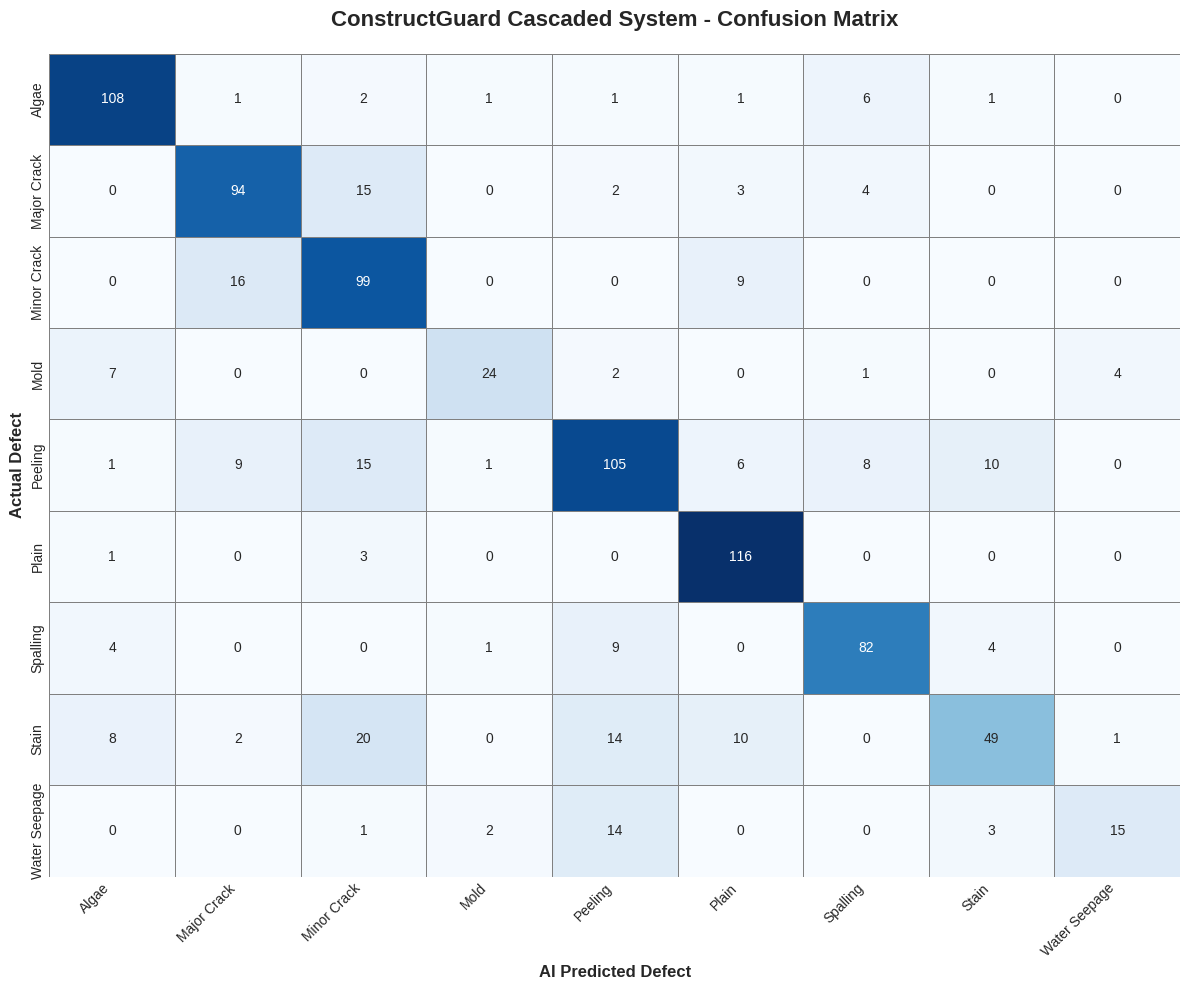

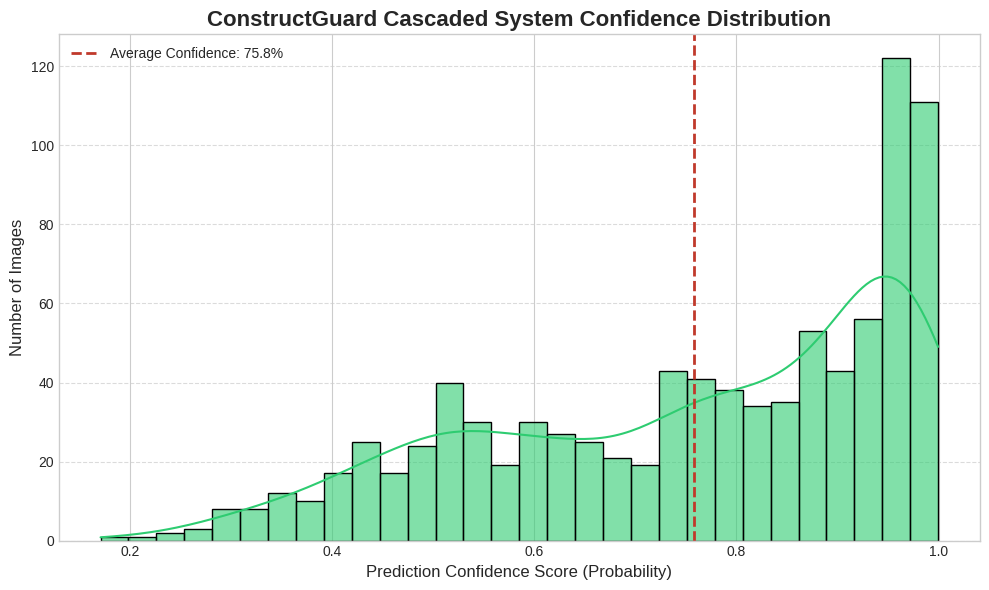

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# ==========================================
# 1. LOAD VALIDATION DATA (NO SHUFFLING)
# ==========================================
print("Preparing Validation Data...")
val_dir = '/content/drive/MyDrive/BD3_original_dataset/train'

datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)
val_data = datagen.flow_from_directory(
    val_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='validation',
    shuffle=False # CRITICAL: Keep false so labels match up!
)

# Standardize 9 classes to match your folder names exactly
cg_classes = ['algae', 'major_crack', 'minor_crack', 'mold', 'peeling', 'plain', 'spalling', 'stain', 'water_seepage']
y_true = val_data.classes

# ==========================================
# 2. RUN CASCADED INFERENCE ON ALL IMAGES
# ==========================================
y_pred = []
confidences = []

print("\nRunning full Cascaded AI Evaluation. This will take a few minutes...")

# Iterate through every batch in the validation set
for i in range(len(val_data)):
    images, labels = val_data[i]

    # Process each image in the batch
    for img_array in images:
        img_array = np.expand_dims(img_array, axis=0) # Add batch dimension

        # Step 1: Router
        router_preds = router_model.predict(img_array, verbose=0)[0]
        router_idx = np.argmax(router_preds)
        broad_category = router_labels[router_idx]
        router_conf = router_preds[router_idx]

        # Step 2: Route to Specialist
        if broad_category == 'Healthy':
            pred_label = 'plain'
            conf = router_conf
        elif broad_category == 'Surface':
            pred_label = 'peeling'
            conf = router_conf
        elif broad_category == 'Moisture':
            spec_preds = moisture_model.predict(img_array, verbose=0)[0]
            spec_idx = np.argmax(spec_preds)
            # Make sure this matches your moisture_labels from the previous cell:
            # ['algae', 'mold', 'stain', 'water_seepage']
            pred_label = moisture_labels[spec_idx].lower().replace(' ', '_')
            conf = router_conf * spec_preds[spec_idx]
        elif broad_category == 'Structural':
            spec_preds = structural_model.predict(img_array, verbose=0)[0]
            spec_idx = np.argmax(spec_preds)
            # Make sure this matches your structural_labels:
            # ['major_crack', 'minor_crack', 'spalling']
            pred_label = structural_labels[spec_idx].lower().replace(' ', '_')
            conf = router_conf * spec_preds[spec_idx]

        # Record the prediction index (0-8) and confidence
        y_pred.append(cg_classes.index(pred_label))
        confidences.append(conf)

print("Evaluation Complete! Generating Reports...\n")

# ==========================================
# 3. CLASSIFICATION REPORT
# ==========================================
print("="*60)
print("     CONSTRUCTGUARD SYSTEM EVALUATION METRICS")
print("="*60)
print(classification_report(y_true, y_pred, target_names=cg_classes))

# ==========================================
# 4. CONFUSION MATRIX
# ==========================================
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 10))
# Clean up names for the plot
clean_classes = [c.replace('_', ' ').title() for c in cg_classes]

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=clean_classes, yticklabels=clean_classes,
            cbar=False, linewidths=0.5, linecolor='gray')
plt.title('ConstructGuard Cascaded System - Confusion Matrix', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Actual Defect', fontsize=12, fontweight='bold')
plt.xlabel('AI Predicted Defect', fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# ==========================================
# 5. KDE + HISTOGRAM OF SYSTEM CONFIDENCE
# ==========================================
plt.figure(figsize=(10, 6))
sns.histplot(confidences, bins=30, kde=True, color='#2ecc71', edgecolor='black', alpha=0.6)

mean_conf = np.mean(confidences)
plt.axvline(mean_conf, color='#c0392b', linestyle='dashed', linewidth=2,
            label=f'Average Confidence: {(mean_conf*100):.1f}%')

plt.title('ConstructGuard Cascaded System Confidence Distribution', fontsize=16, fontweight='bold')
plt.xlabel('Prediction Confidence Score (Probability)', fontsize=12)
plt.ylabel('Number of Images', fontsize=12)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
# Save the models in the modern native Keras format
router_model.save('cg_router.keras')
moisture_model.save('cg_moisture_specialist.keras')
structural_model.save('cg_structural_specialist.keras')

print("Backend files generated: cg_router.keras, cg_moisture_specialist.keras, cg_structural_specialist.keras")

# Download them to your local machine for the backend
from google.colab import files
files.download('cg_router.keras')
files.download('cg_moisture_specialist.keras')
files.download('cg_structural_specialist.keras')

Backend files generated: cg_router.keras, cg_moisture_specialist.keras, cg_structural_specialist.keras


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import io
import numpy as np
import tensorflow as tf
from PIL import Image
from flask import Flask, request, jsonify
import google.generativeai as genai

# Setup
app = Flask(__name__)

# Configure your Gemini API Key
# genai.configure(api_key="YOUR_API_KEY") # User should replace this
model_gemini = genai.GenerativeModel('gemini-1.5-flash') # Using Flash for speed

# Load VGG16 Model
# Based on ConstructGuard.ipynb
# Assume the model is in the same directory
MODEL_PATH = 'ConstructGuard_VGG16_Ultimate.h5'
vgg_model = tf.keras.models.load_model(MODEL_PATH)

# Class Mapping from notebook
CLASSES = [
    'algae', 'major_crack', 'minor_crack', 'mold',
    'peeling', 'plain', 'spalling', 'stain', 'water_seepage'
]

def preprocess_image(image_bytes):
    img = Image.open(io.BytesIO(image_bytes)).convert('RGB')
    img = img.resize((224, 224))
    img_array = np.array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)
    return img_array

def gemini_security_guard(image_pil):
    """
    Checks if the image is construction-related.
    """
    prompt = "Analyze this image. Is it a picture of a construction site, building surface, or structural defect? Answer 'Yes' or 'No' only."
    response = model_gemini.generate_content([prompt, image_pil])
    return response.text.strip().lower().startswith('yes')

def gemini_report_generation(predictions):
    """
    Generates a diagnostic breakdown based on VGG results.
    """
    results_str = ", ".join([f"{k}: {v:.2%}" for k, v in predictions.items()])
    prompt = (
        f"The AI model detected the following construction defects: {results_str}. "
        "Based on these results, please provide: "
        "1. A diagnostic breakdown. "
        "2. An immediate action plan. "
        "3. Recommended ongoing treatment."
    )
    response = model_gemini.generate_content(prompt)
    return response.text

@app.route('/predict', methods=['POST'])
def predict():
    if 'image' not in request.files:
        return jsonify({"error": "No image uploaded"}), 400

    file = request.files['image']
    img_bytes = file.read()
    image_pil = Image.open(io.BytesIO(img_bytes))

    # --- Step 1: Gemini Security Guard ---
    if not gemini_security_guard(image_pil):
        return jsonify({
            "message": "The analysis cannot be carried out because the provided image does not appear to be a valid construction site or building structural component. Please upload a relevant construction-related image."
        }), 400

    # --- Step 2: VGG16 Classification ---
    processed_img = preprocess_image(img_bytes)
    preds = vgg_model.predict(processed_img)[0]

    # Filter results > 15%
    filtered_preds = {CLASSES[i]: float(preds[i]) for i in range(len(CLASSES)) if preds[i] > 0.15}

    if not filtered_preds:
        return jsonify({
            "message": "Analysis complete. No significant defects (above 15% confidence) were detected.",
            "predictions": {CLASSES[i]: float(preds[i]) for i in range(len(CLASSES))}
        })

    # --- Step 3: Gemini Analysis ---
    report = gemini_report_generation(filtered_preds)

    return jsonify({
        "status": "Success",
        "detected_defects": filtered_preds,
        "expert_analysis": report
    })

if __name__ == '__main__':
    app.run(host='0.0.0.0', port=5000)

FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = 'ConstructGuard_VGG16_Ultimate.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

def evaluate_specific_model(model_path, data_dir, model_name, class_labels):
    print(f"\n" + "="*60)
    print(f" EVALUATING: {model_name}")
    print("="*60)

    # 1. Load Model
    model = tf.keras.models.load_model(model_path, compile=False)

    # 2. Setup Validation Data (80/20 split as per your training)
    datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)
    val_flow = datagen.flow_from_directory(
        data_dir,
        target_size=(224, 224),
        batch_size=32,
        class_mode='categorical',
        subset='validation',
        shuffle=False
    )

    # 3. Generate Predictions
    preds = model.predict(val_flow, verbose=1)
    y_pred = np.argmax(preds, axis=1)
    y_true = val_flow.classes
    confidences = np.max(preds, axis=1) # Get the confidence of the chosen class

    # --- VISUALIZATION 1: Classification Report ---
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=class_labels))

    # --- VISUALIZATION 2: Confusion Matrix ---
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_labels, yticklabels=class_labels)
    plt.title(f'Confusion Matrix: {model_name}', fontsize=14)
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()

    # --- VISUALIZATION 3: KDE + Histogram ---
    plt.figure(figsize=(10, 5))
    sns.histplot(confidences, bins=20, kde=True, color='green', alpha=0.5)
    plt.axvline(np.mean(confidences), color='red', linestyle='--', label=f'Mean: {np.mean(confidences):.2f}')
    plt.title(f'Confidence Distribution: {model_name}', fontsize=14)
    plt.xlabel('Confidence Score')
    plt.ylabel('Frequency')
    plt.legend()
    plt.show()

# ==========================================
# EXECUTION: Evaluate all 3 Models
# ==========================================

# 1. THE ROUTER
evaluate_specific_model(
    model_path='cg_router.keras',
    data_dir='/content/drive/MyDrive/ConstructGuard_Cascaded/Router_Data',
    model_name='Router Model (High Level)',
    class_labels=['Healthy', 'Moisture', 'Structural', 'Surface']
)

# 2. MOISTURE SPECIALIST
evaluate_specific_model(
    model_path='cg_moisture_specialist.keras',
    data_dir='/content/drive/MyDrive/ConstructGuard_Cascaded/Moisture_Specialist_Data',
    model_name='Moisture Specialist',
    class_labels=['algae', 'mold', 'stain', 'water_seepage']
)

# 3. STRUCTURAL SPECIALIST
evaluate_specific_model(
    model_path='cg_structural_specialist.keras',
    data_dir='/content/drive/MyDrive/ConstructGuard_Cascaded/Structural_Specialist_Data',
    model_name='Structural Specialist',
    class_labels=['major_crack', 'minor_crack', 'spalling']
)


 EVALUATING: Router Model (High Level)


ValueError: File not found: filepath=cg_router.keras. Please ensure the file is an accessible `.keras` zip file.

In [ ]:
import os

target_path = '/content/drive/MyDrive/ConstructGuard_Cascaded'

def count_files_in_directory(path):
    if not os.path.exists(path):
        print(f"Error: The path '{path}' does not exist. Please ensure your Drive is mounted.")
        return

    print(f"--- File Count Report for: {path} ---\n")

    total_files = 0
    subfolder_counts = {}

    # Walk through the directory
    for root, dirs, files in os.walk(path):
        # Count files in the current directory
        count = len(files)
        total_files += count

        # Store the count for this specific subfolder relative to the target_path
        relative_path = os.path.relpath(root, path)
        subfolder_counts[relative_path] = count

    # Print subfolder breakdown
    for folder, count in sorted(subfolder_counts.items()):
        display_name = "[Root Folder]" if folder == "." else folder
        print(f"Subfolder: {display_name:<50} | Files: {count}")

    print("\n" + "="*60)
    print(f"TOTAL INDIVIDUAL FILES FOUND: {total_files}")
    print("="*60)

# Run the function
count_files_in_directory(target_path)

--- File Count Report for: /content/drive/MyDrive/ConstructGuard_Cascaded ---

Subfolder: [Root Folder]                                      | Files: 0
Subfolder: Moisture_Specialist_Data                           | Files: 0
Subfolder: Moisture_Specialist_Data/algae                     | Files: 609
Subfolder: Moisture_Specialist_Data/mold                      | Files: 192
Subfolder: Moisture_Specialist_Data/stain                     | Files: 521
Subfolder: Moisture_Specialist_Data/water_seepage             | Files: 177
Subfolder: Router_Data                                        | Files: 0
Subfolder: Router_Data/Healthy                                | Files: 600
Subfolder: Router_Data/Moisture                               | Files: 1499
Subfolder: Router_Data/Structural                             | Files: 1717
Subfolder: Router_Data/Surface                                | Files: 776
Subfolder: Structural_Specialist_Data                         | Files: 0
Subfolder: Structural_Speci

In [1]:
import os

target_path = '/content/drive/MyDrive/BD3_original_dataset/train'

def count_files_in_directory(path):
    if not os.path.exists(path):
        print(f"Error: The path '{path}' does not exist. Please ensure your Drive is mounted.")
        return

    print(f"--- File Count Report for: {path} ---\n")

    total_files = 0
    subfolder_counts = {}

    # Walk through the directory
    for root, dirs, files in os.walk(path):
        # Count files in the current directory
        count = len(files)
        total_files += count

        # Store the count for this specific subfolder relative to the target_path
        relative_path = os.path.relpath(root, path)
        subfolder_counts[relative_path] = count

    # Print subfolder breakdown
    for folder, count in sorted(subfolder_counts.items()):
        display_name = "[Root Folder]" if folder == "." else folder
        print(f"Subfolder: {display_name:<50} | Files: {count}")

    print("\n" + "="*60)
    print(f"TOTAL INDIVIDUAL FILES FOUND: {total_files}")
    print("="*60)

# Run the function
count_files_in_directory(target_path)

--- File Count Report for: /content/drive/MyDrive/BD3_original_dataset/train ---

Subfolder: [Root Folder]                                      | Files: 0
Subfolder: algae                                              | Files: 609
Subfolder: major_crack                                        | Files: 593
Subfolder: minor_crack                                        | Files: 624
Subfolder: mold                                               | Files: 192
Subfolder: peeling                                            | Files: 776
Subfolder: plain                                              | Files: 600
Subfolder: spalling                                           | Files: 500
Subfolder: stain                                              | Files: 521
Subfolder: water_seepage                                      | Files: 177

TOTAL INDIVIDUAL FILES FOUND: 4592
